# Tìm keyword Google Maps bằng TF-IDF và Logistic Regression

Mục tiêu là tìm keyword ứng viên liên hệ với rating thấp và giải thích đóng góp trong từng review. Notebook độc lập, đọc trực tiếp `data/raw/ggmap/gmap.json`, theo cùng thiết kế mô hình Foody.

**Quy ước Google Maps:** giữ rating gốc 1–5 sao trong `rating_original`; nhân 2 thành `rating_num` 0–10 để thống nhất quy ước EDA. Nhãn thấp là 1–2 sao; 3–5 sao thuộc nhóm còn lại. Khóa lọc trùng có 4 thành phần: nguồn, quán, rating và nội dung chuẩn hóa. Không dùng ngày đăng hoặc thiết bị bị thiếu làm khóa.

Train/validation/test tách theo `text_norm`, TF-IDF chỉ fit trên phần huấn luyện. Validation chọn C; sau đó fit lại trên development và đánh giá test. Không dùng keyword EDA từ toàn dataset để chọn feature. Support/lift keyword chỉ đo trên development, không chọn bằng test.

Chọn **Restart Kernel and Run All**. Kết quả thực nghiệm, mô hình, cấu hình và CSV được lưu vào thư mục có timestamp trong `notebooks/outputs/logistic_keywords_ggmap`. Cuối notebook có đối chiếu kết quả Foody đã lưu; đây là hai thí nghiệm trong từng nền tảng, không phải thử nghiệm chuyển mô hình giữa hai nguồn.


## 1. Cấu hình thí nghiệm

Đường dẫn mặc định lấy từ notebook EDA. Nếu thư mục `../data/processed` tồn tại thì ưu tiên đường dẫn tương đối để dễ chuyển máy.

- Nhãn `1`: `0 < rating ≤ 5`; nhãn `0`: `5 < rating ≤ 10`.
- TF-IDF dùng regex và n-gram 1–3 như EDA, giữ cả từ phủ định. Regex tách theo token, không phải bộ tách từ tiếng Việt; ví dụ “phục vụ” gồm hai token.
- `min_df=5` và `max_features=100000` giới hạn từ vựng, chỉ fit trên tập huấn luyện tương ứng. Feature hiếm hoặc ngoài giới hạn có thể bị loại.
- Thử `C ∈ {0.1, 1, 10}` trên validation; `C` nhỏ tương ứng regularization mạnh hơn. Dùng trọng số lớp `balanced`, ngưỡng dự đoán 0.5 cố định.
- Ngưỡng support 30, support thấp 10 và lift 2 chỉ dành cho **bảng keyword tham khảo**, không dùng để chọn feature trước khi chia dữ liệu.


In [1]:
from pathlib import Path
import hashlib
import json
import re
import unicodedata
import warnings
from datetime import datetime, timezone

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from scipy.special import expit
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score,
    classification_report, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/raw/ggmap/gmap.json').is_file())
DATA_PATH = ROOT / 'data/raw/ggmap/gmap.json'
OUTPUT_DIR = ROOT / 'notebooks/outputs/logistic_keywords_ggmap'
FOODY_RUN_DIR = ROOT / 'notebooks/outputs/logistic_keywords/20261113T145627_018248Z'
SOURCE_TO_FOODY = {
    'review_id': 'review_id', 'source': 'source_platform',
    'restaurant_id': 'shop_id', 'published_at': 'comment_datetime',
    'rating': 'rating', 'text_raw': 'comment_text',
}
DEDUP_FIELDS = ['source_platform', 'shop_id', 'rating_num', 'text_norm']

SEED = 42
LOW_RATING_THRESHOLD = 5.0
MAX_RATING = 10.0  # Google Maps 1–5 sao đã nhân 2; nhóm thấp là 1–2 sao.
TOKEN_PATTERN = r'(?u)\b\w+\b'
NGRAM_RANGE = (1, 3)
MIN_DF = 5
MAX_FEATURES = 100_000
C_VALUES = (0.1, 1.0, 10.0)
MAX_ITER = 2000
CLASS_WEIGHT = 'balanced'
PREDICTION_THRESHOLD = 0.5
TEST_GROUP_SIZE = 0.20
VALID_GROUP_SIZE_OF_REMAINDER = 0.25
MIN_TOTAL_SUPPORT = 30
MIN_LOW_SUPPORT = 10
MIN_DISPLAY_LIFT = 2.0
TOP_N = 30
CONTEXT_SAMPLE_SIZE = 5

print('scikit-learn:', sklearn.__version__)
print('Dữ liệu:', DATA_PATH)


scikit-learn: 1.9.1
Dữ liệu: D:\FPT\ADY291m\project\data\raw\ggmap\gmap.json


## 2. Đọc và ánh xạ dữ liệu Google Maps

Đọc các trường tương ứng với notebook EDA Maps. Mã nguồn và mã quán giữ dạng chuỗi. Lưu rating gốc để truy vết và tạo rating số bằng cách nhân 2; giá trị thiếu hoặc ngoài 1–5 được báo trong audit. Ngày đăng có thể thiếu; thiết bị không được tạo giả để lọc trùng. Cả review thấp và nhóm còn lại cùng tham gia mô hình.

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(DATA_PATH)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

SOURCE_SHA256 = sha256_file(DATA_PATH)
with DATA_PATH.open(encoding='utf-8-sig') as stream:
    source_records = json.load(stream)
if not isinstance(source_records, list) or not source_records:
    raise ValueError('Google Maps JSON phải là danh sách review không rỗng.')
absent = set(SOURCE_TO_FOODY) - set().union(*(row.keys() for row in source_records))
if absent:
    raise ValueError(f'Thiếu trường nguồn: {sorted(absent)}')
raw = pd.DataFrame.from_records(
    [{target: row.get(source) for source, target in SOURCE_TO_FOODY.items()}
     for row in source_records], columns=list(SOURCE_TO_FOODY.values()),
)
del source_records
for col in ['review_id', 'source_platform', 'shop_id']:
    raw[col] = raw[col].astype('string')
raw['rating_original'] = pd.to_numeric(raw['rating'], errors='coerce')
raw['rating'] = raw['rating_original'] * 2
rating_mapping = raw.groupby('rating_original', dropna=False).size().rename('n_reviews').reset_index()
rating_mapping['rating_scaled'] = rating_mapping['rating_original'] * 2
rating_mapping['is_low_by_rule'] = rating_mapping['rating_original'].between(1, 2)
print(f'Tổng dòng nguồn: {len(raw):,}')
print('SHA-256:', SOURCE_SHA256)
print('Khóa dedup:', DEDUP_FIELDS)
display(rating_mapping)


Tổng dòng nguồn: 147,565
SHA-256: 41bf02e9a65867aead620c0c8373f28b4fc1806ae687ed50de91df526f65265e
Khóa dedup: ['source_platform', 'shop_id', 'rating_num', 'text_norm']


,rating_original,n_reviews,rating_scaled,is_low_by_rule
0,1.0,14784,2.0,True
1,2.0,4777,4.0,True
2,3.0,11096,6.0,False
3,4.0,26042,8.0,False
4,5.0,89856,10.0,False
5,NaN,1010,NaN,False


## 3. Chuẩn bị dữ liệu theo quy tắc EDA Google Maps

Chuẩn hóa NFC, chữ thường và khoảng trắng. Khóa dedup là nền tảng, quán, rating số đã đổi thang và nội dung chuẩn hóa; chỉ loại dòng trùng khi đủ cả 4 thành phần. Dòng thiếu khóa được giữ tại bước dedup, sau đó kiểm tra text và rating. Không yêu cầu ngày đăng hoặc device.

Giữ rating gốc hợp lệ 1–5 sao và văn bản có token. Mọi nhãn thấp phải tương đương rating gốc 1–2 sao. Đây là nhãn rating thay thế, không phải nhãn ngữ nghĩa lời phàn nàn.

In [3]:
MISSING_VALUES = {'', 'unknown', 'none', 'null', 'nan', 'nat', '<na>', 'n/a'}
TOKEN_REGEX = re.compile(TOKEN_PATTERN)

def normalize_text(value):
    if pd.isna(value):
        return ''
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFC', str(value)).lower()).strip()

def prepare_working(source):
    frame = source.copy(deep=True).reset_index(drop=True)
    frame['_source_row'] = np.arange(len(frame))
    frame['rating_num'] = pd.to_numeric(frame['rating'], errors='coerce')
    frame['text_norm'] = frame['comment_text'].map(normalize_text)

    keys = pd.DataFrame(index=frame.index)
    for col in ['source_platform', 'shop_id']:
        values = frame[col].astype('string').str.normalize('NFC').str.strip()
        keys[col] = values.mask(values.str.lower().isin(MISSING_VALUES))
    keys['rating_num'] = frame['rating_num']
    keys['text_norm'] = frame['text_norm'].mask(frame['text_norm'].str.lower().isin(MISSING_VALUES))
    complete_key = keys.notna().all(axis=1)
    duplicate_mask = complete_key & keys.duplicated(keep='first')
    clean = frame.loc[~duplicate_mask].copy()

    valid = clean['text_norm'].ne('') & clean['rating_original'].between(1, 5)
    corpus = clean.loc[valid].copy()
    corpus['n_tokens'] = corpus['text_norm'].map(lambda text: len(TOKEN_REGEX.findall(text)))
    zero_rating = corpus['rating_num'].eq(0)
    zero_tokens = corpus['n_tokens'].eq(0)
    working = corpus.loc[~(zero_rating | zero_tokens)].copy().reset_index(drop=True)
    working['is_low'] = working['rating_num'].le(LOW_RATING_THRESHOLD).astype(np.int8)

    audit = pd.Series({
        'Dòng nguồn': len(frame),
        'Thiếu khóa lọc trùng, được giữ ở bước dedup': int((~complete_key).sum()),
        'Dòng trùng bị loại': int(duplicate_mask.sum()),
        'Dòng sau dedup': len(clean),
        'Dòng rỗng text hoặc rating không hợp lệ, sau dedup': int((~valid).sum()),
        'Rating 0 trong corpus hợp lệ': int(zero_rating.sum()),
        'Comment 0 token trong corpus hợp lệ': int(zero_tokens.sum()),
        'Đồng thời rating 0 và 0 token': int((zero_rating & zero_tokens).sum()),
        'Dòng cuối cùng': len(working),
    }, name='Số review')
    if working.empty or working['is_low'].nunique() != 2:
        raise ValueError('Cần dữ liệu sau lọc có đủ cả hai nhóm rating.')
    assert working['rating_original'].between(1, 5).all()
    assert working['is_low'].eq(working['rating_original'].le(2)).all()
    assert working['rating_num'].eq(working['rating_original'] * 2).all()
    assert working['n_tokens'].gt(0).all()
    assert not working['_source_row'].isin(frame.loc[duplicate_mask, '_source_row']).any()
    return working, audit

working, cleaning_audit = prepare_working(raw)
display(cleaning_audit.to_frame())
display(working.groupby('is_low').agg(
    n_reviews=('is_low', 'size'), n_unique_texts=('text_norm', 'nunique'),
))
print(f'Tỷ lệ điểm thấp sau lọc: {working["is_low"].mean():.2%}')


,Số review
Dòng nguồn,147565
"Thiếu khóa lọc trùng, được giữ ở bước dedup",16544
Dòng trùng bị loại,669
Dòng sau dedup,146896
"Dòng rỗng text hoặc rating không hợp lệ, sau dedup",16544
Rating 0 trong corpus hợp lệ,0
Comment 0 token trong corpus hợp lệ,82
Đồng thời rating 0 và 0 token,0
Dòng cuối cùng,130270


,n_reviews,n_unique_texts
is_low,,
0,112064,106881
1,18206,17911


Tỷ lệ điểm thấp sau lọc: 13.98%


## 4. Tách train, validation và test theo nhóm nội dung

Tách test trước, rồi tách train/validation từ phần còn lại. Các review cùng `text_norm` luôn ở cùng một tập. Khoảng 60/20/20 là tỷ lệ **nhóm nội dung**, số review thực tế có thể khác. Seed cố định, không thử nhiều seed rồi chọn kết quả đẹp. Nếu tập nào thiếu lớp thì dừng để xem lại thiết kế chia dữ liệu.

Train dùng fit TF-IDF và hệ số. Validation chọn `C`. Sau đó fit lại trên train + validation; test chỉ dùng đánh giá cuối. Các ứng viên lift cũ được chọn từ toàn dataset không được dùng để lọc feature ở đây, vì có thể đã nhìn thấy test.

Chia theo nội dung chỉ ngăn nguyên câu chuẩn hóa lặp giữa các tập; chưa ngăn câu gần giống, cùng quán hoặc cùng thời điểm. Kết quả không chứng minh khả năng tổng quát sang quán mới.


,split,n_reviews,n_unique_texts,low_count,low_pct
0,train,78614,74813,10905,13.87
1,validation,25632,24938,3693,14.41
2,test,26024,24938,3608,13.86


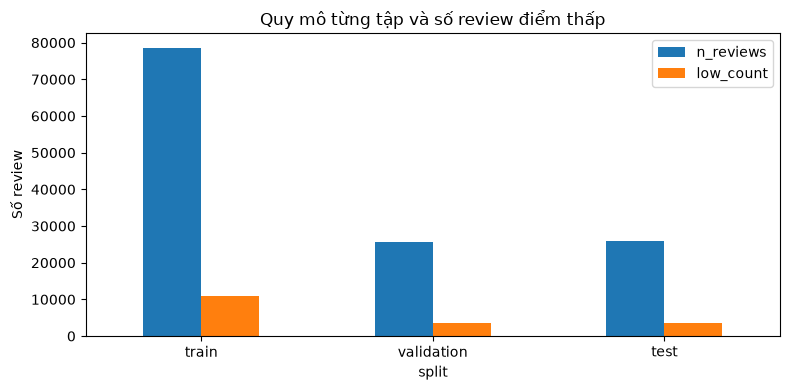

Đã kiểm tra không giao text_norm giữa train, validation và test.


In [4]:
outer_split = GroupShuffleSplit(n_splits=1, test_size=TEST_GROUP_SIZE, random_state=SEED)
dev_pos, test_pos = next(outer_split.split(working, groups=working['text_norm']))
development = working.iloc[dev_pos].copy()
test = working.iloc[test_pos].copy()

inner_split = GroupShuffleSplit(
    n_splits=1, test_size=VALID_GROUP_SIZE_OF_REMAINDER, random_state=SEED + 1,
)
train_pos, valid_pos = next(inner_split.split(development, groups=development['text_norm']))
train = development.iloc[train_pos].copy()
validation = development.iloc[valid_pos].copy()

parts = {'train': train, 'validation': validation, 'test': test}
for name, part in parts.items():
    if part['is_low'].nunique() != 2:
        raise ValueError(f'{name} thiếu một lớp; cần xem lại cách chia và lượng dữ liệu.')
for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert set(parts[a]['text_norm']).isdisjoint(parts[b]['text_norm'])
assert sum(len(part) for part in parts.values()) == len(working)

split_report = pd.DataFrame([
    {'split': name, 'n_reviews': len(part), 'n_unique_texts': part['text_norm'].nunique(),
     'low_count': int(part['is_low'].sum()), 'low_pct': part['is_low'].mean() * 100}
    for name, part in parts.items()
])
display(split_report.round(2))
split_report.plot.bar(x='split', y=['n_reviews', 'low_count'], rot=0, figsize=(8, 4))
plt.title('Quy mô từng tập và số review điểm thấp')
plt.ylabel('Số review')
plt.tight_layout()
plt.show()

assert set(train['text_norm']).isdisjoint(test['text_norm'])
print('Đã kiểm tra không giao text_norm giữa train, validation và test.')


## 5. Xây Pipeline và các chỉ số đánh giá

Pipeline nối `TfidfVectorizer` với Logistic Regression. Mỗi review là một hàng của ma trận thưa. Mỗi feature có một cột TF-IDF và một hệ số; không chuyển toàn bộ ma trận sang dense.

Với `y=1` là điểm thấp: `z = b + Σ(w_j x_j)` và `p_low = sigmoid(z)`. L2 làm co hệ số, thường không đặt chính xác tất cả feature yếu bằng 0; mô hình không tự chọn duy nhất một keyword.

Chọn `C` bằng **macro-F1 validation**. Báo cáo precision/recall/F1 nhóm thấp, accuracy, ROC-AUC và average precision (AP) để xem thêm. AP là average precision theo đường precision-recall, không gọi là diện tích hình thang. Với `class_weight='balanced'`, xác suất có thể chưa hiệu chỉnh tốt; không diễn giải trực tiếp thành tỷ lệ thật ngoài thực tế.


In [5]:
def make_pipeline(c):
    return Pipeline([
        ('tfidf', TfidfVectorizer(
            token_pattern=TOKEN_PATTERN, ngram_range=NGRAM_RANGE,
            lowercase=False, min_df=MIN_DF, max_features=MAX_FEATURES,
            norm='l2', smooth_idf=True, sublinear_tf=False,
        )),
        ('lr', LogisticRegression(
            C=float(c), solver='liblinear', class_weight=CLASS_WEIGHT,
            max_iter=MAX_ITER, random_state=SEED,
        )),
    ])

def fit_checked(model, texts, y):
    # Không âm thầm dùng một mô hình chưa hội tụ để kết luận về hệ số.
    with warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        try:
            return model.fit(texts, y)
        except ConvergenceWarning as exc:
            raise RuntimeError(
                'Logistic Regression chưa hội tụ. Tăng MAX_ITER rồi chạy lại từ phần 5.'
            ) from exc
        except ValueError as exc:
            if 'vocabulary' in str(exc).lower() or 'terms remain' in str(exc).lower():
                raise ValueError('Từ vựng rỗng: kiểm tra dữ liệu hoặc giảm MIN_DF.') from exc
            raise

def metric_row(y_true, pred, probabilities):
    return {
        'accuracy': accuracy_score(y_true, pred),
        'macro_f1': f1_score(y_true, pred, average='macro', zero_division=0),
        'precision_low': precision_score(y_true, pred, zero_division=0),
        'recall_low': recall_score(y_true, pred, zero_division=0),
        'f1_low': f1_score(y_true, pred, zero_division=0),
        'roc_auc': roc_auc_score(y_true, probabilities),
        'average_precision_low': average_precision_score(y_true, probabilities),
    }

def predict_low(model, texts):
    class_index = list(model.classes_).index(1)
    probabilities = model.predict_proba(texts)[:, class_index]
    return (probabilities >= PREDICTION_THRESHOLD).astype(np.int8), probabilities


## 6. Train và chọn C chỉ bằng validation

Mỗi lần fit chỉ nhận train. Validation chỉ được `transform` bằng từ vựng/IDF của train. Các mô hình có cùng cấu hình từ vựng và khác mức regularization. Khi macro-F1 bằng nhau, ưu tiên `C` nhỏ hơn. Chưa dự đoán test ở bước này.


In [6]:
validation_rows = []
for c in C_VALUES:
    candidate_model = fit_checked(make_pipeline(c), train['text_norm'], train['is_low'])
    valid_pred, valid_prob = predict_low(candidate_model, validation['text_norm'])
    validation_rows.append({
        'C': c,
        'n_features': len(candidate_model.named_steps['tfidf'].get_feature_names_out()),
        **metric_row(validation['is_low'], valid_pred, valid_prob),
    })
    print(f'C={c}: validation macro-F1 = {validation_rows[-1]["macro_f1"]:.4f}')

validation_results = pd.DataFrame(validation_rows).sort_values(
    ['macro_f1', 'C'], ascending=[False, True], kind='stable',
).reset_index(drop=True)
best_c = float(validation_results.iloc[0]['C'])
display(validation_results.round(4))
print('C được chọn:', best_c)


C=0.1: validation macro-F1 = 0.8719


C=1.0: validation macro-F1 = 0.8910


C=10.0: validation macro-F1 = 0.8997


,C,n_features,accuracy,macro_f1,precision_low,recall_low,f1_low,roc_auc,average_precision_low
0,10.0,100000,0.9481,0.8997,0.7853,0.8803,0.8301,0.9782,0.9019
1,1.0,100000,0.9408,0.8910,0.7353,0.9201,0.8174,0.9798,0.9039
2,0.1,100000,0.9284,0.8719,0.6894,0.9161,0.7867,0.9759,0.8861


C được chọn: 10.0


## 7. Fit mô hình cuối trên train + validation

Sau khi chốt `C`, fit lại cả TF-IDF và Logistic Regression trên development = train + validation. Từ vựng, IDF và hệ số có thể thay đổi so với mô hình ở bước 6. Từ bước này trở đi, mọi bảng keyword và giải thích review đều dùng **cùng mô hình cuối**.

Tập `reference` dùng thống kê keyword chính là development; không lấy test để chọn keyword. Đây là thống kê trong tập đã dùng huấn luyện, chưa phải kiểm chứng độc lập keyword.


In [7]:
reference = development.copy()
final_model = fit_checked(make_pipeline(best_c), reference['text_norm'], reference['is_low'])
vectorizer = final_model.named_steps['tfidf']
classifier = final_model.named_steps['lr']
assert list(classifier.classes_) == [0, 1]
feature_names = vectorizer.get_feature_names_out()
coefficients = classifier.coef_[0]
bias = float(classifier.intercept_[0])
X_reference = vectorizer.transform(reference['text_norm']).tocsr()
assert X_reference.shape[1] == len(coefficients) == len(feature_names)
print(f'Số feature = số hệ số: {len(feature_names):,}')
print(f'Kích thước TF-IDF development: {X_reference.shape}')
print(f'Tỷ lệ phần tử khác 0: {X_reference.nnz / np.prod(X_reference.shape):.4%}')
print(f'Bias: {bias:.6f}')


Số feature = số hệ số: 100,000
Kích thước TF-IDF development: (104246, 100000)
Tỷ lệ phần tử khác 0: 0.0740%
Bias: -1.202824


## 8. Đánh giá cuối trên test và so với baseline

So với DummyClassifier luôn chọn lớp phổ biến của development. Test chỉ dùng để đo chất lượng phân loại rating và đọc lỗi sau khi mô hình đã chốt. Không dùng điểm test để đổi `C`, ngưỡng hoặc chọn danh sách keyword. Nếu cải tiến dựa trên lỗi test, cần một tập test mới cho đánh giá độc lập tiếp theo.

Các thước đo dưới đây đánh giá **phân loại review**, chưa đánh giá độ chính xác của keyword hay khả năng hiểu phủ định. Một review đoán đúng vẫn có thể được giải thích bằng cụm không mang ý chê.


,model,accuracy,macro_f1,precision_low,recall_low,f1_low,roc_auc,average_precision_low
0,Dummy: lớp phổ biến,0.8614,0.4628,0.0000,0.0000,0.0000,0.5000,0.1386
1,TF-IDF + Logistic Regression,0.9489,0.8981,0.7809,0.8772,0.8263,0.9752,0.8964


                  precision    recall  f1-score   support

Còn lại: 3–5 sao       0.98      0.96      0.97     22416
   Thấp: 1–2 sao       0.78      0.88      0.83      3608

        accuracy                           0.95     26024
       macro avg       0.88      0.92      0.90     26024
    weighted avg       0.95      0.95      0.95     26024



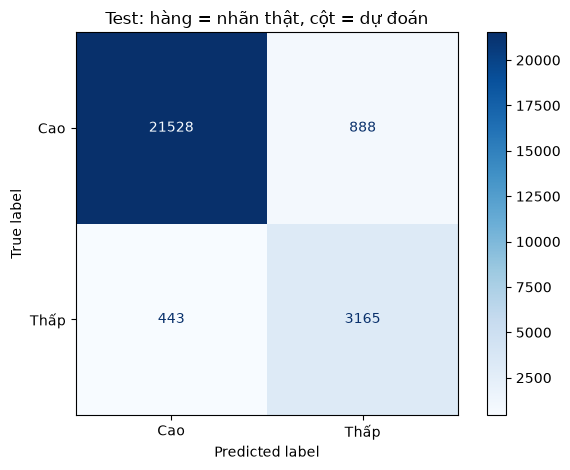

Review test không có feature trong từ vựng: 7


In [8]:
test_pred, test_prob = predict_low(final_model, test['text_norm'])
dummy = DummyClassifier(strategy='prior', random_state=SEED)
dummy.fit(np.zeros((len(reference), 1)), reference['is_low'])
dummy_pred = dummy.predict(np.zeros((len(test), 1)))
dummy_prob = dummy.predict_proba(np.zeros((len(test), 1)))[:, list(dummy.classes_).index(1)]
test_results = pd.DataFrame([
    {'model': 'Dummy: lớp phổ biến', **metric_row(test['is_low'], dummy_pred, dummy_prob)},
    {'model': 'TF-IDF + Logistic Regression', **metric_row(test['is_low'], test_pred, test_prob)},
])
display(test_results.round(4))
print(classification_report(
    test['is_low'], test_pred, labels=[0, 1],
    target_names=['Còn lại: 3–5 sao', 'Thấp: 1–2 sao'], zero_division=0,
))
ConfusionMatrixDisplay.from_predictions(
    test['is_low'], test_pred, labels=[0, 1],
    display_labels=['Cao', 'Thấp'], cmap='Blues', values_format='d',
)
plt.title('Test: hàng = nhãn thật, cột = dự đoán')
plt.tight_layout()
plt.show()

X_test_audit = vectorizer.transform(test['text_norm'])
print('Review test không có feature trong từ vựng:', int((X_test_audit.getnnz(axis=1) == 0).sum()))
del X_test_audit


## 9. Tạo bảng trọng số và đối chiếu support/lift

Một dòng tương ứng một feature. `coefficient >0` đẩy log-odds về nhóm thấp; `<0` đẩy về nhóm cao. Độ lớn hệ số chỉ nên so sánh trong cùng mô hình và cách biểu diễn.

- `support_reference`: số review development chứa cụm, mỗi review tối đa 1.
- `low_support_reference`: số review thấp development chứa cụm.
- `p_low_given_term`: tỷ lệ thấp trong các review chứa cụm.
- `lift_reference`: `p_low_given_term / tỷ lệ thấp development`.
- `mean_logit_contribution`: trung bình `w_j × x_j` trên **tất cả** review development, gồm cả giá trị 0.

Lift xét liên hệ riêng của cụm với rating; hệ số được học đồng thời với nhiều feature. Chúng có thể khác hướng vì các n-gram thường chồng lấn hoặc tương quan. Hệ số không chứng minh quan hệ nhân quả. Lift ở đây được tính mới trên development, không phải kết quả kiểm tra ổn định 5 split của notebook EDA.


A. Hệ số dương cao, đủ support; chưa áp điều kiện lift


,keyword,n_tokens,coefficient,support_reference,low_support_reference,p_low_given_term,lift_reference,mean_logit_contribution,meets_support
0,tệ,1,18.3086,4246,3699,0.8712,6.2211,0.0704,True
1,dở,1,11.0991,1593,1093,0.6861,4.8997,0.0184,True
2,không,1,10.3003,38843,7137,0.1837,1.3121,0.2001,True
3,chém,1,9.2150,187,100,0.5348,3.8188,0.0024,True
4,dỡ,1,8.6726,126,110,0.8730,6.2343,0.0021,True
5,thái độ,2,8.5626,4139,2998,0.7243,5.1725,0.0285,True
6,ok lắm,2,8.0232,184,15,0.0815,0.5822,0.0022,True
7,kém,1,7.6394,1319,923,0.6998,4.9972,0.0112,True
9,bẩn,1,7.4256,623,396,0.6356,4.5391,0.0056,True
10,1 sao,2,6.8430,373,274,0.7346,5.2458,0.0024,True


B. Cùng danh sách A, thêm điều kiện lift ≥ 2.0


,keyword,n_tokens,coefficient,support_reference,low_support_reference,p_low_given_term,lift_reference,mean_logit_contribution,meets_support
0,tệ,1,18.3086,4246,3699,0.8712,6.2211,0.0704,True
1,dở,1,11.0991,1593,1093,0.6861,4.8997,0.0184,True
3,chém,1,9.2150,187,100,0.5348,3.8188,0.0024,True
4,dỡ,1,8.6726,126,110,0.8730,6.2343,0.0021,True
5,thái độ,2,8.5626,4139,2998,0.7243,5.1725,0.0285,True
7,kém,1,7.6394,1319,923,0.6998,4.9972,0.0112,True
9,bẩn,1,7.4256,623,396,0.6356,4.5391,0.0056,True
10,1 sao,2,6.8430,373,274,0.7346,5.2458,0.0024,True
11,mắc,1,6.8195,1374,596,0.4338,3.0976,0.0091,True
12,rất tệ,2,6.7808,625,582,0.9312,6.6498,0.0042,True


C. Feature hướng về nhóm điểm cao — để đối chiếu


,keyword,n_tokens,coefficient,support_reference,low_support_reference,p_low_given_term,lift_reference,mean_logit_contribution,meets_support
99999,hơi,1,-11.0762,13788,798,0.0579,0.4133,-0.0917,True
99998,nhanh,1,-10.5278,8211,343,0.0418,0.2983,-0.0563,True
99997,không bị,2,-9.2661,1308,23,0.0176,0.1256,-0.0085,True
99996,dễ,1,-9.0844,10627,319,0.0300,0.2144,-0.0630,True
99995,ok,1,-8.9947,6841,627,0.0917,0.6545,-0.0571,True
99994,chill,1,-8.3325,3316,63,0.0190,0.1357,-0.0269,True
99993,gian,1,-7.8248,23338,1266,0.0542,0.3874,-0.0918,True
99992,không gian,2,-7.6910,21654,905,0.0418,0.2985,-0.0861,True
99991,ổn,1,-7.5436,9457,756,0.0799,0.5709,-0.0544,True
99990,tình,1,-7.5320,17565,711,0.0405,0.2891,-0.0845,True


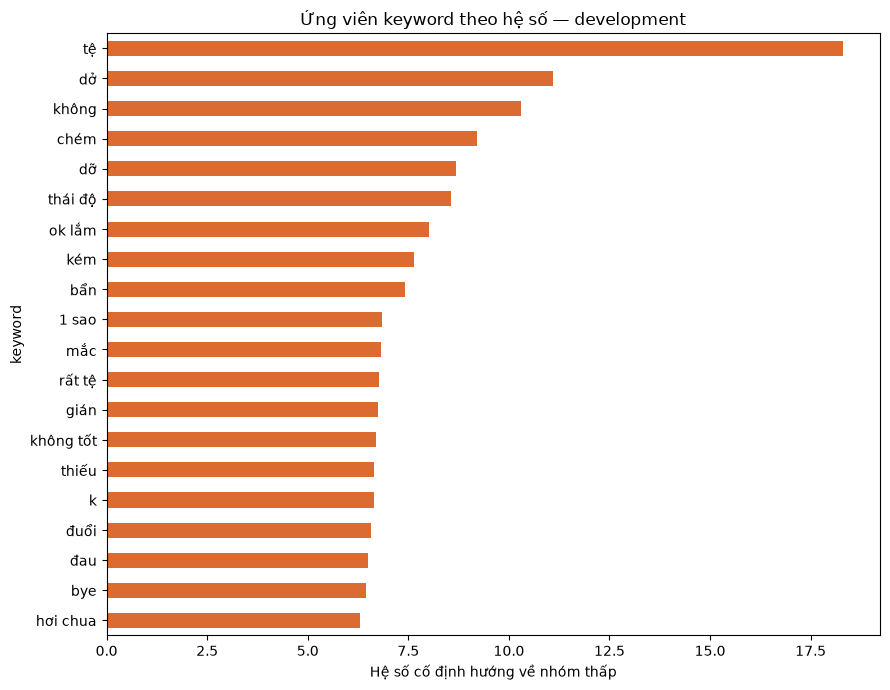

In [9]:
support = np.asarray((X_reference > 0).sum(axis=0)).ravel().astype(np.int64)
low_mask = reference['is_low'].to_numpy(dtype=bool)
low_support = np.asarray((X_reference[low_mask] > 0).sum(axis=0)).ravel().astype(np.int64)
baseline_reference = float(reference['is_low'].mean())
p_low_given_term = np.divide(
    low_support, support, out=np.full(len(support), np.nan), where=support > 0,
)
feature_table = pd.DataFrame({
    'keyword': feature_names,
    'n_tokens': [len(term.split()) for term in feature_names],
    'coefficient': coefficients,
    'support_reference': support,
    'low_support_reference': low_support,
    'p_low_given_term': p_low_given_term,
    'lift_reference': p_low_given_term / baseline_reference,
    'mean_logit_contribution': coefficients * np.asarray(X_reference.mean(axis=0)).ravel(),
})
feature_table['meets_support'] = (
    feature_table['support_reference'].ge(MIN_TOTAL_SUPPORT)
    & feature_table['low_support_reference'].ge(MIN_LOW_SUPPORT)
)
feature_table = feature_table.sort_values('coefficient', ascending=False).reset_index(drop=True)
keyword_candidates = feature_table.loc[
    feature_table['coefficient'].gt(0) & feature_table['meets_support']
].copy()
keyword_with_lift = keyword_candidates.loc[
    keyword_candidates['lift_reference'].ge(MIN_DISPLAY_LIFT)
].copy()

print('A. Hệ số dương cao, đủ support; chưa áp điều kiện lift')
display(keyword_candidates.head(TOP_N).round(4))
print('B. Cùng danh sách A, thêm điều kiện lift ≥', MIN_DISPLAY_LIFT)
display(keyword_with_lift.head(TOP_N).round(4))
print('C. Feature hướng về nhóm điểm cao — để đối chiếu')
display(feature_table.loc[
    feature_table['coefficient'].lt(0)
    & feature_table['support_reference'].ge(MIN_TOTAL_SUPPORT)
].sort_values('coefficient').head(15).round(4))
if keyword_candidates.empty:
    print('Không có ứng viên đạt ngưỡng support. Xem feature_table; chưa đủ bằng chứng ở ngưỡng hiện tại.')

plot_terms = keyword_candidates.head(20).sort_values('coefficient')
if not plot_terms.empty:
    plot_terms.plot.barh(x='keyword', y='coefficient', figsize=(9, 7), legend=False, color='#dc6b32')
    plt.xlabel('Hệ số cố định hướng về nhóm thấp')
    plt.title('Ứng viên keyword theo hệ số — development')
    plt.tight_layout()
    plt.show()


## 10. Đọc ngữ cảnh thật của từng keyword

Dùng chính analyzer/từ vựng của TF-IDF để tìm review chứa feature; tránh tìm chuỗi con sai ranh giới token. Lấy mẫu ở cả nhóm thấp và cao. Đồng thời đếm số nội dung khác nhau và số quán đóng góp để phát hiện cụm chủ yếu xuất hiện nhờ một câu lặp hoặc một quán.

Một cụm trọng số lớn có thể là tên quán, địa danh hoặc mảnh câu thiếu nghĩa. Cần đọc trước khi gọi nó là “keyword diễn đạt sự không hài lòng”. Không tự động suy ra ngữ nghĩa từ dấu hệ số.


In [10]:
def keyword_context(term, n=CONTEXT_SAMPLE_SIZE):
    term = normalize_text(term)
    feature_id = vectorizer.vocabulary_.get(term)
    if feature_id is None:
        print(f'{term!r} không có feature trong từ vựng cuối.')
        return pd.DataFrame()
    hit_positions = X_reference[:, feature_id].nonzero()[0]
    rows = reference.iloc[hit_positions].copy()
    print('Keyword:', term)
    print('Hệ số:', float(coefficients[feature_id]))
    print('Số review:', len(rows), '| Số nội dung:', rows['text_norm'].nunique(),
          '| Số quán:', rows['shop_id'].nunique())
    if not rows.empty:
        concentration = rows['text_norm'].value_counts(normalize=True).iloc[0]
        print(f'Tỷ trọng review từ một nội dung phổ biến nhất: {concentration:.1%}')
    selected = []
    for label in (1, 0):
        group = rows.loc[rows['is_low'].eq(label)]
        if not group.empty:
            selected.append(group.sample(min(n, len(group)), random_state=SEED))
    if not selected:
        return pd.DataFrame()
    result = pd.concat(selected)[['_source_row', 'shop_id', 'rating_num', 'is_low', 'comment_text']]
    with pd.option_context('display.max_colwidth', None):
        display(result)
    return result

# Có thể thay bằng một keyword cụ thể: keyword_context('phục vụ chậm').
if not keyword_candidates.empty:
    context_example = keyword_context(keyword_candidates.iloc[0]['keyword'])


Keyword: tệ
Hệ số: 18.308632811663944
Số review: 4246 | Số nội dung: 4169 | Số quán: 1202
Tỷ trọng review từ một nội dung phổ biến nhất: 0.9%


,_source_row,shop_id,rating_num,is_low,comment_text
35402,39894,gmap:9b4350c246ffbee6bcb976d5,2.0,1,"Phục vụ rất tệ , không quan tâm khách ,ly thì không có đá, chẳng có tăm và giấy ,. Thôi thì 1 sao"
84363,95388,gmap:3ae3bae41551bd2b4b835c0d,2.0,1,"Dịch vụ quá tệ, món lâu đợi 2 tiếng\nNếu quán đông người mn nên né vì đồ ăn ra rất lâu"
10472,11818,gmap:63f8f7e359d7e6c52cf37adc,2.0,1,"Trải nghiệm rất tệ , đồ ăn ra rất lâu , dù chỉ gọi 2 món , một món xào lăn , 1 món lẩu . Ăn xong món xào , lẩu thì khoảng 1 tiếng sau mới mang ra , mình tưởng đang ninh đồ cho mềm nhưng khi lên đồ chắc cũng vừa kịp chín thôi . NV thì ngó lơ khách hàng ( chắc tại mình order ít quá ) 🤔"
123274,139636,gmap:7addf7d2b0836ad121ac20fe,2.0,1,"Trải nghiệm rất tệ, gọi lẩu bò lại có dê hôi ko thể ăn nổi, nhưng ko đc đổi, nhân viên phục vụ chậm, hờ hững, gọi như điếc"
27562,31060,gmap:24f3e58d68ca842a033f3a0d,2.0,1,"Nhân viên quán cọc như quỉ, nước cũng dở gọi 2 ly hồng trà sữa uống kh khác gì trà sữa bình thường nhưng giá cao hơn, trà sữa khoai môn thì nhạt bỏ quá ít đá, nói chung quán được cái không gian thôi chứ mọi thứ tệ 🫩 …"
40633,45794,gmap:abd496489333cedadc8309dc,10.0,0,"nếu như mng muốn thử những món ăn hương vị của đài loan thì có thể đến Haochi Dimsum nha, đồ ăn kh quá tệ, tui siu rì com men món há cảo sò điệp và vịt quay😋. Nhà hàng có 2 kh gian, khu bên ngoài thì thông thoáng mang lại cảm giác thoải mái cho khách hàng phù hợp cho bàn đông người, khu bên trong thì ấm cúng hơn phù hợp cho những cặp đôi hay gia đình nhỏ😙"
19040,21471,gmap:e261088b6a6142c21539e30a,10.0,0,Không như mong muốn nhưng cũng không tệ. Chủ yếu gia vị đối với tôi không hợp.
86458,97766,gmap:b214918101e1edcfdfecbdb2,8.0,0,"Đồ uống bình thường, mặc dù không tệ. Nhưng trong không gian khá sang chảnh như thế, không nên phục vụ bằng cốc kiểu mang đi và rất nhiều ống hút."
21933,24728,gmap:9bf874ab92919c2a51c3adb0,8.0,0,"Ấn tượng đầu tiên là không gian rất đẹp, trang trí có gu, nhìn vào là thấy chăm chút. Quán theo phong cách xưa gần gũi thiên nhiên, nhiều cây xanh, thoáng và dễ chịu, ngồi lâu vẫn cảm thấy thoải mái chứ không bí bách.\nNhân viên phục vụ dễ thương, nói chuyện nhẹ nhàng, thân thiện và hỗ trợ khá nhanh. Đây là điểm mình đánh giá cao vì tạo cảm giác được chào đón ngay từ đầu.\nVề món ăn, theo cảm nhận cá nhân thì ở mức bình thường. Không tệ, trình bày ổn, ăn được nhưng chưa có món nào thật sự nổi bật hay gây ấn tượng mạnh. Nếu kỳ vọng cao về ẩm thực thì có thể sẽ thấy hơi thiếu điểm nhấn.\n\nTổng thể chỗ hẹn gặp bạn bè rất ổn."
87911,99414,gmap:0f498b56dcf0296cc98899aa,8.0,0,"Quán phục vụ ok. Giá mắc hơn so với lúc mới mở nhưng vẫn còn ổn chưa cao lắm. Đồ ăn ngon, chỉ là nhà vệ sinh hơi tệ xí."


## 11. Giải thích một review bằng TF-IDF × trọng số

`explain_review()` trả về từng feature **thực sự xuất hiện trong vector** cùng `tfidf`, `coefficient` và `contribution`. Cột `coefficient` cố định cho mọi câu, còn TF-IDF và đóng góp thay đổi theo câu.

Hàm kiểm tra `bias + tổng contribution = decision_function` của mô hình. Các bảng top dương/âm chỉ là phần hiển thị; tổng kiểm tra luôn dùng toàn bộ feature hoạt động. Đóng góp đo trên thang logit, không phải số điểm phần trăm xác suất, và không trực tiếp so với nhau như xác suất độc lập.

N-gram chồng lấn cùng đóng góp: “phục”, “vụ”, “chậm”, “phục vụ”, “vụ chậm”, “phục vụ chậm” có thể cùng xuất hiện nếu có trong từ vựng. Không gộp chúng tùy ý rồi coi đó là đóng góp duy nhất của cả cụm. Nếu toàn bộ token nằm ngoài từ vựng, dự đoán chỉ dựa vào bias.


In [11]:
def explain_review(text, top_k=10, show=True):
    text_norm = normalize_text(text)
    x = vectorizer.transform([text_norm]).tocsr()
    ids = x.indices
    values = x.data
    contributions = values * coefficients[ids]
    explanation = pd.DataFrame({
        'feature': feature_names[ids], 'tfidf': values,
        'coefficient': coefficients[ids], 'contribution': contributions,
    }).sort_values('contribution', ascending=False).reset_index(drop=True)
    logit = float(final_model.decision_function([text_norm])[0])
    probability = float(final_model.predict_proba([text_norm])[0, 1])
    reconstructed_logit = bias + float(contributions.sum())
    assert np.isclose(reconstructed_logit, logit, atol=1e-8)
    assert np.isclose(expit(logit), probability, atol=1e-8)
    summary = {
        'text_norm': text_norm,
        'active_features': int(x.nnz),
        'bias': bias,
        'sum_contributions': float(contributions.sum()),
        'logit': logit,
        'p_low_model': probability,
        'predicted_is_low': int(probability >= PREDICTION_THRESHOLD),
    }
    if show:
        print('Review:', text)
        display(pd.Series(summary, name='Giá trị').to_frame())
        if explanation.empty:
            print('Không có feature hoạt động. Mô hình chỉ sử dụng bias.')
        else:
            print('Feature đẩy về nhóm thấp:')
            display(explanation.loc[explanation['contribution'].gt(0)].head(top_k).round(6))
            print('Feature đẩy về nhóm cao:')
            display(explanation.loc[explanation['contribution'].lt(0)].tail(top_k).sort_values('contribution').round(6))
            print('Tổng đóng góp đã kiểm tra với decision_function của mô hình.')
    return summary, explanation

CUSTOM_REVIEW = 'Đồ ăn ngon nhưng phục vụ chậm, đợi rất lâu.'
custom_summary, custom_explanation = explain_review(CUSTOM_REVIEW)


Review: Đồ ăn ngon nhưng phục vụ chậm, đợi rất lâu.


,Giá trị
text_norm,"đồ ăn ngon nhưng phục vụ chậm, đợi rất lâu."
active_features,25
bias,-1.202824
sum_contributions,3.89478
logit,2.691956
p_low_model,0.93655
predicted_is_low,1


Feature đẩy về nhóm thấp:


,feature,tfidf,coefficient,contribution
0,rất lâu,0.229494,4.092428,0.939187
1,đợi,0.172154,5.232799,0.900847
2,chậm,0.184852,4.061656,0.750806
3,đợi rất,0.295209,2.163930,0.638812
4,ăn ngon nhưng,0.252570,2.304366,0.582014
5,đợi rất lâu,0.300605,1.908142,0.573597
6,lâu,0.144847,3.290848,0.476670
7,vụ chậm,0.257456,1.702188,0.438238
8,ngon nhưng phục,0.324851,1.219707,0.396222
9,đồ ăn,0.089224,2.436663,0.217408


Feature đẩy về nhóm cao:


,feature,tfidf,coefficient,contribution
24,ngon nhưng,0.195857,-6.349040,-1.243503
23,ăn ngon,0.111578,-7.158121,-0.798687
22,đồ ăn ngon,0.125204,-4.632886,-0.580055
21,rất,0.085520,-2.556781,-0.218656
20,ngon,0.063349,-2.766662,-0.175266
19,ăn,0.064645,-1.141033,-0.073762
18,nhưng,0.097425,-0.285256,-0.027791
17,đồ,0.076029,-0.251883,-0.019150


Tổng đóng góp đã kiểm tra với decision_function của mô hình.


## 12. Thử phủ định và xem giới hạn ngữ cảnh

Các câu sau chỉ là ví dụ chẩn đoán, không có nhãn rating và không tham gia fit hay báo cáo điểm test. Chạy để quan sát thay vì áp sẵn kết luận. N-gram có thể biểu diễn một số phủ định gần, nhưng mô hình tuyến tính không bảo đảm hiểu phủ định dài, nhiều khía cạnh hoặc mỉa mai.

Do chuẩn hóa L2, thêm một từ còn có thể thay đổi TF-IDF của những từ đã có. Vì vậy chênh lệch xác suất giữa hai câu không chỉ do một hệ số mới. Tìm keyword bằng hệ số vẫn cần đánh giá ngữ cảnh thủ công.


In [12]:
diagnostic_texts = [
    'Nhân viên thiếu tôn trọng khách.',
    'Không hề có chuyện nhân viên thiếu tôn trọng khách.',
    'Đồ ăn ngon nhưng nhân viên thiếu tôn trọng khách.',
    'Phục vụ chậm.',
    'Phục vụ không chậm.',
]
diagnostic_rows = []
for text in diagnostic_texts:
    summary, _ = explain_review(text, show=False)
    diagnostic_rows.append({'review': text, **summary})
display(pd.DataFrame(diagnostic_rows)[['review', 'active_features', 'p_low_model', 'predicted_is_low']])

# Bỏ dấu # nếu muốn xem đầy đủ đóng góp của câu phủ định.
# explain_review(diagnostic_texts[1])


,review,active_features,p_low_model,predicted_is_low
0,Nhân viên thiếu tôn trọng khách.,14,0.992968,1
1,Không hề có chuyện nhân viên thiếu tôn trọng k...,24,0.998454,1
2,Đồ ăn ngon nhưng nhân viên thiếu tôn trọng khách.,26,0.839034,1
3,Phục vụ chậm.,6,0.937785,1
4,Phục vụ không chậm.,7,0.995191,1


## 13. Đọc lỗi phân loại sau khi chốt mô hình

Lấy các dự đoán sai có độ tự tin cao để tìm giả thuyết lỗi: rating lệch nội dung, khen/chê lẫn nhau, từ ngoài từ vựng, phủ định hoặc tên quán. Các mẫu tự tin cao không đại diện cho toàn bộ lỗi. Có thể gọi `explain_review()` với một review sai để xem mô hình dựa vào feature nào.

Đây là phân tích test sau đánh giá, không dùng để chỉnh mô hình rồi báo lại cùng test như kết quả độc lập.


In [13]:
test_predictions = test[['_source_row', 'shop_id', 'rating_original', 'rating_num', 'comment_text', 'text_norm', 'is_low']].copy()
test_predictions['predicted_is_low'] = test_pred
test_predictions['p_low_model'] = test_prob
test_predictions['correct'] = test_predictions['is_low'].eq(test_pred)
test_predictions['confidence_predicted_class'] = np.where(test_pred == 1, test_prob, 1 - test_prob)
errors = test_predictions.loc[~test_predictions['correct']].sort_values(
    'confidence_predicted_class', ascending=False,
)
with pd.option_context('display.max_colwidth', 180):
    display(errors.head(15))
if not errors.empty:
    error_summary, error_explanation = explain_review(errors.iloc[0]['comment_text'])
else:
    print('Không có lỗi trong tập test hiện tại; vẫn cần kiểm tra tính đại diện và rò rỉ dữ liệu.')


,_source_row,shop_id,rating_original,rating_num,comment_text,text_norm,is_low,predicted_is_low,p_low_model,correct,confidence_predicted_class
84616,95683,gmap:49774ccdcdb5478c9c9d684b,5.0,10.0,Quá tệ,quá tệ,0,1,0.999996,False,0.999996
47027,53026,gmap:1ccfa5dceec4dc7eb44a1100,1.0,2.0,"Không gian tuyệt vời, view biển thoáng đãng. Cafe ngon đậm đà ,nhân viên nhiệt tình thân thiện.","không gian tuyệt vời, view biển thoáng đãng. cafe ngon đậm đà ,nhân viên nhiệt tình thân thiện.",1,0,0.000055,False,0.999945
34770,39198,gmap:9a622d8174f6d652fa4276f3,3.0,6.0,"Tạm, phục vụ quá tệ.","tạm, phục vụ quá tệ.",0,1,0.999833,False,0.999833
112300,127100,gmap:13d3b1f41d56d7faa892eabf,3.0,6.0,"Phục vụ quá tệ, nhân viên thái độ khó chịu với khách hàng","phục vụ quá tệ, nhân viên thái độ khó chịu với khách hàng",0,1,0.999830,False,0.999830
29268,32977,gmap:2ba0265e663ced9117c3e789,2.0,4.0,Ăn ngon,ăn ngon,1,0,0.000204,False,0.999796
25946,29242,gmap:f137c31689f41198a12c8731,3.0,6.0,Đợi rất lâu trong khi ngta vào sau thì dc trc tệ:)),đợi rất lâu trong khi ngta vào sau thì dc trc tệ:)),0,1,0.999685,False,0.999685
66533,75226,gmap:5d9e6b0adf3873ed15db041f,3.0,6.0,"Đồ ăn mắc, không tươi","đồ ăn mắc, không tươi",0,1,0.999498,False,0.999498
36070,40646,gmap:c086c316d16b9b09fa43c3c4,3.0,6.0,"Phục vụ quá tệ, nhân viên không cần khách","phục vụ quá tệ, nhân viên không cần khách",0,1,0.999495,False,0.999495
107769,121926,gmap:c001e4f48b18f4e0752611d3,3.0,6.0,"Lần đầu ăn cho nhánh này cho gần nhà và cái kết ko hề đớn hơn.\n- 20h mình tới và 20h15 quầy line ko còn 1 cái gì từ khoai tây chiên với trà sữa, đến cả các loại sốt và salad c...","lần đầu ăn cho nhánh này cho gần nhà và cái kết ko hề đớn hơn. - 20h mình tới và 20h15 quầy line ko còn 1 cái gì từ khoai tây chiên với trà sữa, đến cả các loại sốt và salad cũ...",0,1,0.999484,False,0.999484
126052,142799,gmap:91d4a2be96165967b96c0eba,1.0,2.0,Ngon rẻ,ngon rẻ,1,0,0.000544,False,0.999456


Review: Quá tệ


,Giá trị
text_norm,quá tệ
active_features,3
bias,-1.202824
sum_contributions,13.664324
logit,12.4615
p_low_model,0.999996
predicted_is_low,1


Feature đẩy về nhóm thấp:


,feature,tfidf,coefficient,contribution
0,tệ,0.548178,18.308633,10.036383
1,quá tệ,0.727594,3.602889,2.621440
2,quá,0.412442,2.440346,1.006501


Feature đẩy về nhóm cao:


,feature,tfidf,coefficient,contribution


Tổng đóng góp đã kiểm tra với decision_function của mô hình.


## 14. Tạo phiếu đánh giá keyword thủ công

Để đánh giá đúng mục tiêu cuối, lấy mẫu ngữ cảnh từ development cho top keyword và đánh dấu thủ công:

- `is_complaint_in_context`: `1` khi cụm trong ngữ cảnh đang thể hiện ý chê, `0` khi không; bỏ trống nếu chưa gán nhãn.
- `aspect`: ví dụ phục vụ, đồ ăn, giá, vệ sinh hoặc khác.
- `annotation_notes`: phủ định, mỉa mai, mảnh câu, tên riêng, trường hợp mơ hồ.

Rating không tự điền nhãn ngữ nghĩa này. Phiếu có cột nguồn và rating để tiện kiểm tra; khi đánh giá mù, nên ẩn các cột đó trong bản gán nhãn. Đây là mẫu đọc thủ công của **top keyword**, không phải đánh giá chất lượng trích xuất trên mọi review. Tỷ lệ gán nhãn “ý chê” chưa đo recall hoặc phát hiện keyword bị bỏ sót; các dòng cùng review/keyword có thể phụ thuộc nhau.


In [14]:
annotation_rows = []
for term in keyword_candidates.head(TOP_N)['keyword']:
    feature_id = vectorizer.vocabulary_[term]
    positions = X_reference[:, feature_id].nonzero()[0]
    pool = reference.iloc[positions]
    selected = pool.sample(min(CONTEXT_SAMPLE_SIZE, len(pool)), random_state=SEED)
    for _, row in selected.iterrows():
        annotation_rows.append({
            'keyword': term, 'source_row': int(row['_source_row']),
            'shop_id': row['shop_id'], 'rating_num': row['rating_num'],
            'comment_text': row['comment_text'],
            'is_complaint_in_context': '', 'aspect': '', 'annotation_notes': '',
        })
annotation_template = pd.DataFrame(annotation_rows, columns=[
    'keyword', 'source_row', 'shop_id', 'rating_num', 'comment_text',
    'is_complaint_in_context', 'aspect', 'annotation_notes',
])
print('Số dòng cần đọc và gán nhãn:', len(annotation_template))
display(annotation_template.head(10))


Số dòng cần đọc và gán nhãn: 150


,keyword,source_row,shop_id,rating_num,comment_text,is_complaint_in_context,aspect,annotation_notes
0,tệ,127481,gmap:57af768d31ab90a791af6bcc,4.0,"Tốc độ làm và ship đồ ăn siêu chậm, shop phải ...",,,
1,tệ,68423,gmap:13a772579a8009a998222d01,2.0,Tệ hết sức! Vỏ xíu mại khô khốc & chai như bị ...,,,
2,tệ,33149,gmap:5eed72cd41de305a436f9cc6,4.0,nhân viên thái độ coi khách không ra gì khách ...,,,
3,tệ,108042,gmap:a5d2daceda846e1cef855a38,2.0,Phục vụ chán từ gửi xe đến khi ngồi xuống. Bàn...,,,
4,tệ,4218,gmap:a6e8c79f242ae8e6f1320c54,2.0,Phục vụ rất tệ luôn. Mình cả bạn ngồi đúng 1 t...,,,
5,dở,85376,gmap:dbd86f4c434f5dad3d05d63e,4.0,Mình mua cho bạn gái mình uống mà bạn gái mình...,,,
6,dở,103480,gmap:7ef9d04eef71e534a525a28c,4.0,Dở vậy sao đông hay zay tr 🥲 Dĩa bò rất là ít ...,,,
7,dở,118338,gmap:9b22a66a37dde81b8ac24d71,2.0,😡😡tôi nghĩ chỗ này nên dẹp tiệm là vừa-\ntự ch...,,,
8,dở,33591,gmap:ffceee8cd48b0a9a2fcc7ad0,4.0,Nói chung trải nghiệm ko tốt . Cách phục vụ dở...,,,
9,dở,146974,gmap:57e2373d8125a3bf937e9bfc,2.0,khi mình tới quán thấy trên bàn có 1 con GIÁN ...,,,


## 15. Lưu kết quả, mô hình và cấu hình

Lưu bundle gồm mô hình cuối và các tham số cần để dùng lại. TF-IDF đã lưu từ vựng/IDF; Logistic Regression đã lưu hệ số/bias. Khi dự đoán mới phải dùng đúng bundle, không fit lại TF-IDF riêng cho câu mới. Chỉ load file joblib từ nguồn tin cậy.

Các CSV tách rõ danh sách feature, ứng viên, bảng thêm điều kiện lift, dự đoán test và phiếu gán nhãn. Thư mục output có timestamp để không ghi đè kết quả lần chạy trước. `split_assignment.csv` và SHA-256 dữ liệu giúp đối chiếu thí nghiệm; version thư viện và seed cũng được lưu.


In [15]:
assert sha256_file(DATA_PATH) == SOURCE_SHA256, 'Dữ liệu nguồn đã đổi trong lúc chạy.'
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

run_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
run_dir = OUTPUT_DIR / run_stamp
run_dir.mkdir(parents=True, exist_ok=False)
split_assignment = pd.concat([
    part[['_source_row', 'text_norm', 'is_low']].assign(split=name)
    for name, part in parts.items()
]).sort_values('_source_row')
tables = {
    'cleaning_audit.csv': cleaning_audit.rename_axis('item').reset_index(),
    'split_report.csv': split_report,
    'split_assignment.csv': split_assignment,
    'validation_metrics.csv': validation_results,
    'test_metrics.csv': test_results,
    'all_feature_weights.csv': feature_table,
    'keyword_candidates.csv': keyword_candidates,
    'keyword_candidates_lift_ge_2.csv': keyword_with_lift,
    'test_predictions.csv': test_predictions,
    'keyword_annotation_template.csv': annotation_template,
    'custom_review_contributions.csv': custom_explanation,
    'diagnostic_predictions.csv': pd.DataFrame(diagnostic_rows),
    'confusion_matrix.csv': pd.DataFrame(
        __import__('sklearn.metrics', fromlist=['confusion_matrix']).confusion_matrix(
            test['is_low'], test_pred, labels=[0, 1]),
        index=['true_other', 'true_low'], columns=['pred_other', 'pred_low'],
    ).rename_axis('actual').reset_index(),
    'rating_mapping.csv': rating_mapping,
}
for filename, table in tables.items():
    table.to_csv(run_dir / filename, index=False, encoding='utf-8-sig')

config = {
    'seed': SEED, 'data_path': str(DATA_PATH), 'data_sha256': SOURCE_SHA256,
    'sklearn_version': sklearn.__version__, 'numpy_version': np.__version__,
    'pandas_version': pd.__version__, 'low_rating_threshold': LOW_RATING_THRESHOLD,
    'max_rating': MAX_RATING, 'dedup_fields': DEDUP_FIELDS,
    'source_platform': 'Google Maps', 'rating_scale_factor': 2,
    'original_rating_range': [1, 5], 'low_original_ratings': [1, 2],
    'solver': 'liblinear', 'tfidf_norm': 'l2',
    'split_method': 'GroupShuffleSplit', 'split_group': 'text_norm',
    'validation_seed': SEED + 1, 'python_version': __import__('sys').version,
    'token_pattern': TOKEN_PATTERN, 'ngram_range': NGRAM_RANGE,
    'min_df': MIN_DF, 'max_features': MAX_FEATURES, 'class_weight': CLASS_WEIGHT,
    'C_values': C_VALUES, 'selected_C': best_c, 'max_iter': MAX_ITER,
    'prediction_threshold': PREDICTION_THRESHOLD,
    'test_group_size': TEST_GROUP_SIZE,
    'valid_group_size_of_remainder': VALID_GROUP_SIZE_OF_REMAINDER,
    'min_total_support': MIN_TOTAL_SUPPORT, 'min_low_support': MIN_LOW_SUPPORT,
    'min_display_lift': MIN_DISPLAY_LIFT,
    'n_features': len(feature_names), 'keyword_reference': 'train_plus_validation_only',
    'created_at_utc': run_stamp,
}
with (run_dir / 'experiment_config.json').open('w', encoding='utf-8') as stream:
    json.dump(config, stream, ensure_ascii=False, indent=2)
joblib.dump({'pipeline': final_model, 'config': config}, run_dir / 'logistic_keywords.joblib')
print('Đã lưu kết quả vào:', run_dir.resolve())
display(pd.DataFrame({'file': sorted(path.name for path in run_dir.iterdir())}))


Đã lưu kết quả vào: D:\FPT\ADY291m\project\notebooks\outputs\logistic_keywords_ggmap\20261115T093431_080713Z


,file
0,all_feature_weights.csv
1,cleaning_audit.csv
2,confusion_matrix.csv
3,custom_review_contributions.csv
4,diagnostic_predictions.csv
5,experiment_config.json
6,keyword_annotation_template.csv
7,keyword_candidates.csv
8,keyword_candidates_lift_ge_2.csv
9,logistic_keywords.joblib


## 16. Diễn giải và phạm vi kết luận

Đánh giá phân loại rating và đánh giá ngữ nghĩa keyword là hai mục tiêu khác nhau. Nhãn thấp của Maps là 1–2 sao; 3 sao thuộc nhóm còn lại trong quy ước này. Chia theo text_norm ngăn nội dung chuẩn hóa trùng qua các tập nhưng không bảo đảm quán mới, thời điểm mới hoặc câu gần giống.

Hệ số phụ thuộc từ vựng, regularization và các feature tương quan. Lift development là thống kê trong tập đã dùng fit mô hình; không phải kiểm chứng ổn định 5 lần như EDA. Các phiếu keyword cần đọc ngữ cảnh để xác định ý chê; không sử dụng điểm phân loại thay cho đánh giá ngữ nghĩa.

So sánh dưới đây đối chiếu **hai mô hình cùng phương pháp được huấn luyện riêng trên hai nguồn**, không phải hai thuật toán ML khác nhau. Chênh lệch điểm còn phụ thuộc phân bố rating, độ dài review, ngưỡng nhãn và quy tắc dedup. Không suy ra quan hệ nhân quả hoặc hiệu quả chuyển nền tảng từ phép so sánh này.

## 17. Kết quả thực nghiệm và đối chiếu Foody

Các bảng dưới được tạo từ lần chạy hiện tại và CSV kết quả Foody đã lưu. Không chọn lại C hay keyword theo điểm test. Không so sánh trực tiếp độ lớn hệ số của hai mô hình như một thang đo chung.

In [16]:
from IPython.display import Markdown

comparison_parts = [test_results.assign(platform='Google Maps')]
if (FOODY_RUN_DIR / 'test_metrics.csv').is_file():
    comparison_parts.insert(0, pd.read_csv(FOODY_RUN_DIR / 'test_metrics.csv').assign(platform='Foody'))
comparison_metrics = pd.concat(comparison_parts, ignore_index=True)
display(comparison_metrics[['platform', 'model', 'accuracy', 'macro_f1', 'precision_low', 'recall_low', 'f1_low', 'roc_auc', 'average_precision_low']].round(4))
comparison_metrics.to_csv(run_dir / 'platform_test_comparison.csv', index=False, encoding='utf-8-sig')
keyword_preview = keyword_with_lift.head(10)[['keyword', 'coefficient', 'support_reference', 'low_support_reference', 'lift_reference']]
display(keyword_preview.round(4))
lr_result = test_results.loc[test_results['model'].eq('TF-IDF + Logistic Regression')].iloc[0]
dummy_result = test_results.loc[test_results['model'].str.startswith('Dummy')].iloc[0]
cm = __import__('sklearn.metrics', fromlist=['confusion_matrix']).confusion_matrix(test['is_low'], test_pred, labels=[0, 1])
experiment_summary = {
    'platform': 'Google Maps', 'run_dir': str(run_dir.resolve()),
    'source_rows': int(len(raw)), 'working_rows': int(len(working)),
    'low_count': int(working['is_low'].sum()), 'low_pct': float(working['is_low'].mean() * 100),
    'selected_C': best_c, 'feature_count': int(len(feature_names)),
    'candidate_count': int(len(keyword_candidates)), 'candidate_lift_ge_2_count': int(len(keyword_with_lift)),
    'test_confusion_matrix': cm.tolist(), 'test_zero_features': int((vectorizer.transform(test['text_norm']).getnnz(axis=1) == 0).sum()),
    'source_sha256': SOURCE_SHA256, 'model_test_metrics': lr_result.to_dict(),
    'dummy_test_metrics': dummy_result.to_dict(),
}
with (run_dir / 'experiment_summary.json').open('w', encoding='utf-8') as stream:
    json.dump(experiment_summary, stream, ensure_ascii=False, indent=2)
summary_text = (
    f"### Nhận xét từ lần chạy Google Maps\n\n"
    f"- Dữ liệu: {len(raw):,} review nguồn, {len(working):,} review sau lọc; nhóm 1–2 sao chiếm {working['is_low'].mean():.2%}.\n"
    f"- Validation chọn C = {best_c:g}; mô hình cuối có {len(feature_names):,} đặc trưng.\n"
    f"- Test macro-F1 = {lr_result['macro_f1']:.4f}, so với baseline {dummy_result['macro_f1']:.4f}.\n"
    f"- Precision/recall/F1 nhóm thấp = {lr_result['precision_low']:.4f}/{lr_result['recall_low']:.4f}/{lr_result['f1_low']:.4f}.\n"
    f"- Ma trận test: đúng nhóm còn lại {cm[0,0]:,}; báo nhầm thấp {cm[0,1]:,}; bỏ sót thấp {cm[1,0]:,}; phát hiện đúng thấp {cm[1,1]:,}.\n"
    f"- Có {len(keyword_candidates):,} ứng viên hệ số dương đủ support; {len(keyword_with_lift):,} ứng viên đạt thêm lift ≥2.\n\n"
    "Kết quả này đo phân loại rating trên nội dung chuẩn hóa chưa xuất hiện trong development. Các ứng viên keyword vẫn cần đọc ngữ cảnh; biểu đồ và ví dụ phủ định ở trên hỗ trợ kiểm tra giới hạn mô hình."
)
display(Markdown(summary_text))
(run_dir / 'run_summary.md').write_text(summary_text, encoding='utf-8')


,platform,model,accuracy,macro_f1,precision_low,recall_low,f1_low,roc_auc,average_precision_low
0,Foody,Dummy: lớp phổ biến,0.8261,0.4524,0.0000,0.0000,0.0000,0.5000,0.1739
1,Foody,TF-IDF + Logistic Regression,0.8774,0.8076,0.6149,0.7903,0.6917,0.9242,0.7658
2,Google Maps,Dummy: lớp phổ biến,0.8614,0.4628,0.0000,0.0000,0.0000,0.5000,0.1386
3,Google Maps,TF-IDF + Logistic Regression,0.9489,0.8981,0.7809,0.8772,0.8263,0.9752,0.8964


,keyword,coefficient,support_reference,low_support_reference,lift_reference
0,tệ,18.3086,4246,3699,6.2211
1,dở,11.0991,1593,1093,4.8997
3,chém,9.2150,187,100,3.8188
4,dỡ,8.6726,126,110,6.2343
5,thái độ,8.5626,4139,2998,5.1725
7,kém,7.6394,1319,923,4.9972
9,bẩn,7.4256,623,396,4.5391
10,1 sao,6.8430,373,274,5.2458
11,mắc,6.8195,1374,596,3.0976
12,rất tệ,6.7808,625,582,6.6498


### Nhận xét từ lần chạy Google Maps

- Dữ liệu: 147,565 review nguồn, 130,270 review sau lọc; nhóm 1–2 sao chiếm 13.98%.
- Validation chọn C = 10; mô hình cuối có 100,000 đặc trưng.
- Test macro-F1 = 0.8981, so với baseline 0.4628.
- Precision/recall/F1 nhóm thấp = 0.7809/0.8772/0.8263.
- Ma trận test: đúng nhóm còn lại 21,528; báo nhầm thấp 888; bỏ sót thấp 443; phát hiện đúng thấp 3,165.
- Có 8,062 ứng viên hệ số dương đủ support; 5,228 ứng viên đạt thêm lift ≥2.

Kết quả này đo phân loại rating trên nội dung chuẩn hóa chưa xuất hiện trong development. Các ứng viên keyword vẫn cần đọc ngữ cảnh; biểu đồ và ví dụ phủ định ở trên hỗ trợ kiểm tra giới hạn mô hình.

671